# Loan Default Risk Analysis — EDA

**Business question:** which LendingClub loan applications should a lender approve, at what grade / rate / amount / term — and which should it decline or price higher?

Data: LendingClub accepted loans, 2007–2018Q4 (Kaggle). Default = Charged Off / Default; Fully Paid = repaid. Loans still Current, Late or In Grace Period are excluded from default-rate denominators because their outcome is not known yet.

In [ ]:
import duckdb
con = duckdb.connect('data/loans.duckdb', read_only=True)
print(con.execute("SELECT COUNT(*) FROM resolved").fetchone())  # resolved loans

## Default rate by grade with the average interest rate charged (line)

Default rate by grade with the average interest rate charged (line).

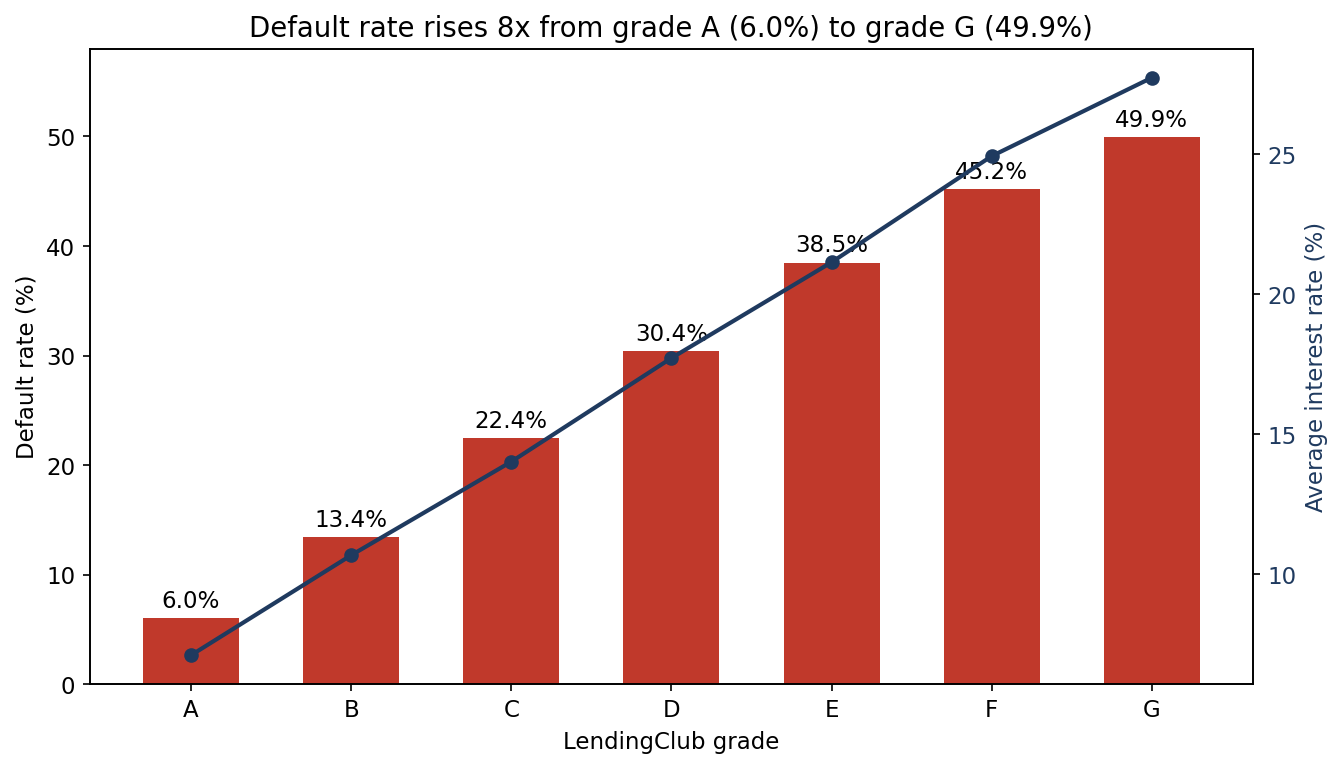

In [ ]:
# see sql/ for the query behind this chart
from IPython.display import Image
Image('images/default_rate_by_grade.png')

## Default rate (%) by FICO band and DTI band

Default rate (%) by FICO band and DTI band. Only 2 resolved loans had FICO <650 — approved loans start at ~660.

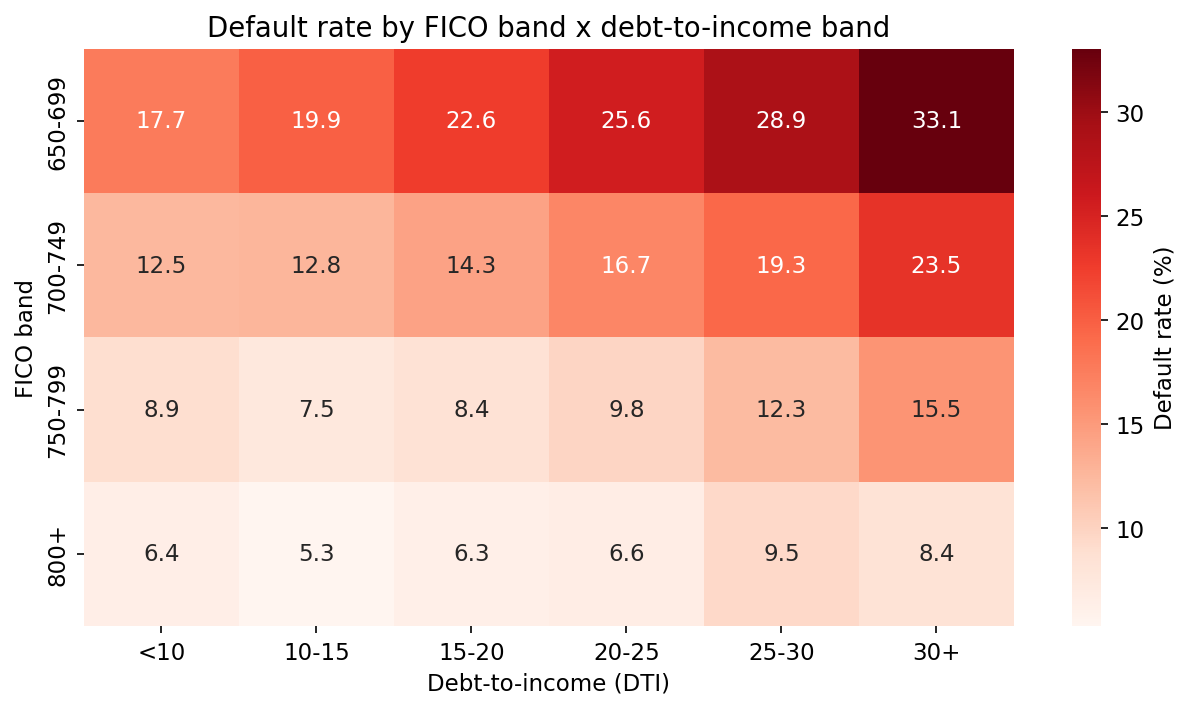

In [ ]:
# see sql/ for the query behind this chart
from IPython.display import Image
Image('images/fico_x_dti_heatmap.png')

## Default rate by stated loan purpose, with loan counts

Default rate by stated loan purpose, with loan counts.

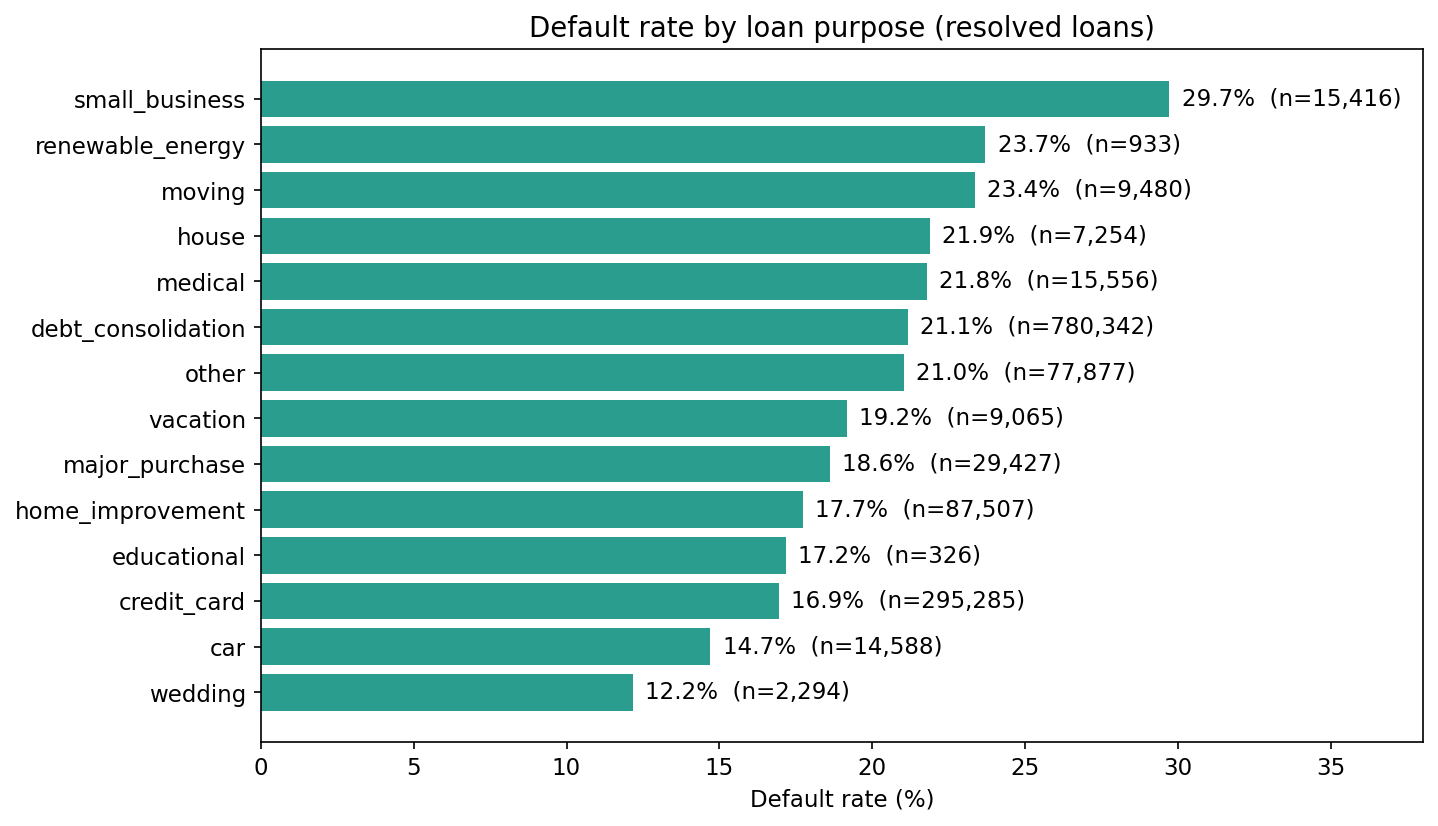

In [ ]:
# see sql/ for the query behind this chart
from IPython.display import Image
Image('images/default_rate_by_purpose.png')

## Default rate by issue year

Default rate by issue year. 2017-2018 look lower partly because most of those loans are still Current and excluded.

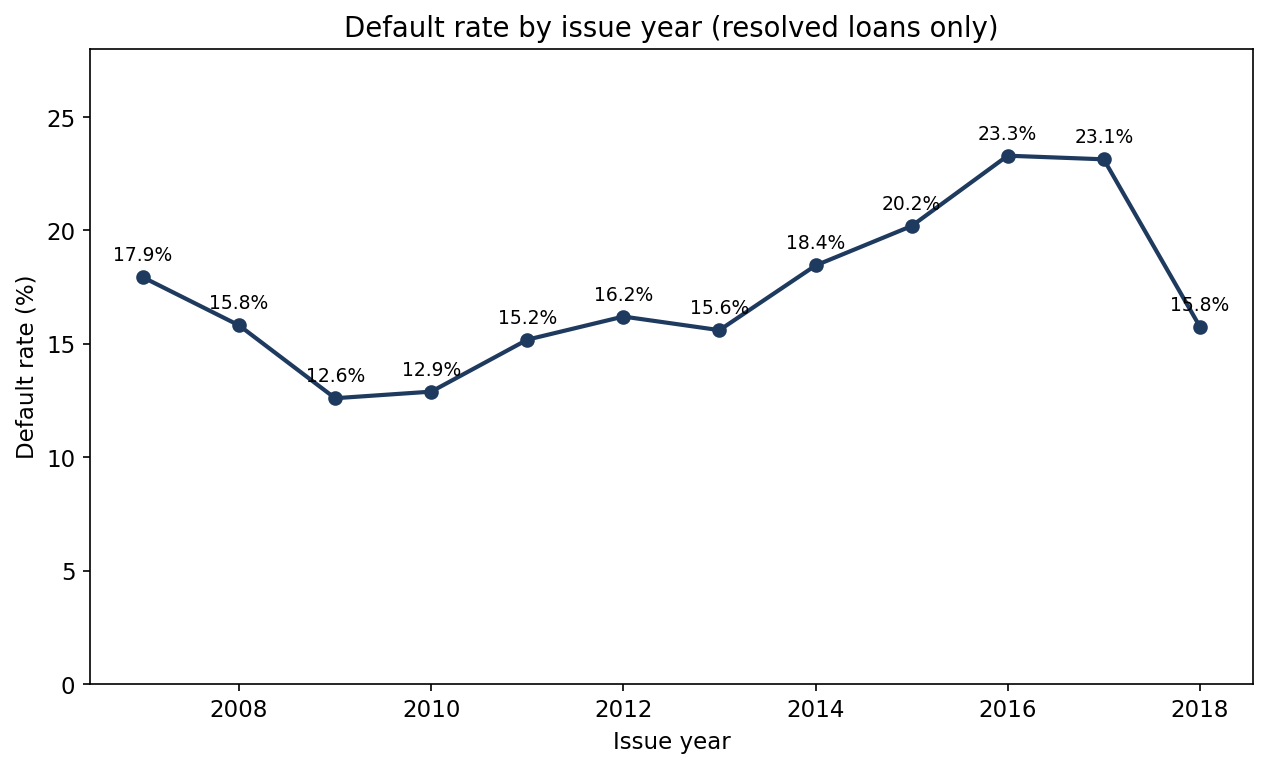

In [ ]:
# see sql/ for the query behind this chart
from IPython.display import Image
Image('images/default_rate_by_year.png')

## Default rate by grade and term: 60-month loans default at roughly double the 36-month rate in every grade

Default rate by grade and term: 60-month loans default at roughly double the 36-month rate in every grade.

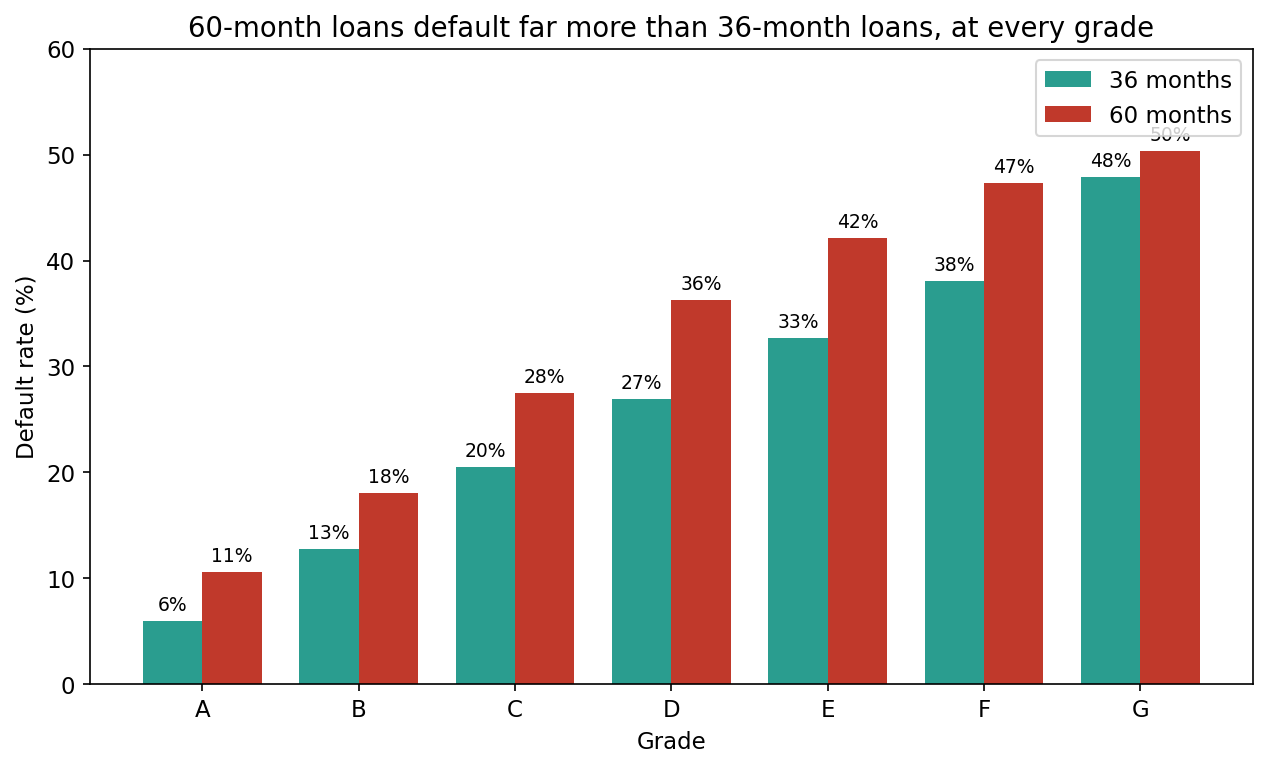

In [ ]:
# see sql/ for the query behind this chart
from IPython.display import Image
Image('images/default_rate_by_term_grade.png')

## Net principal lost (funded $ minus principal recovered) on defaulted loans, by grade

Net principal lost (funded $ minus principal recovered) on defaulted loans, by grade.

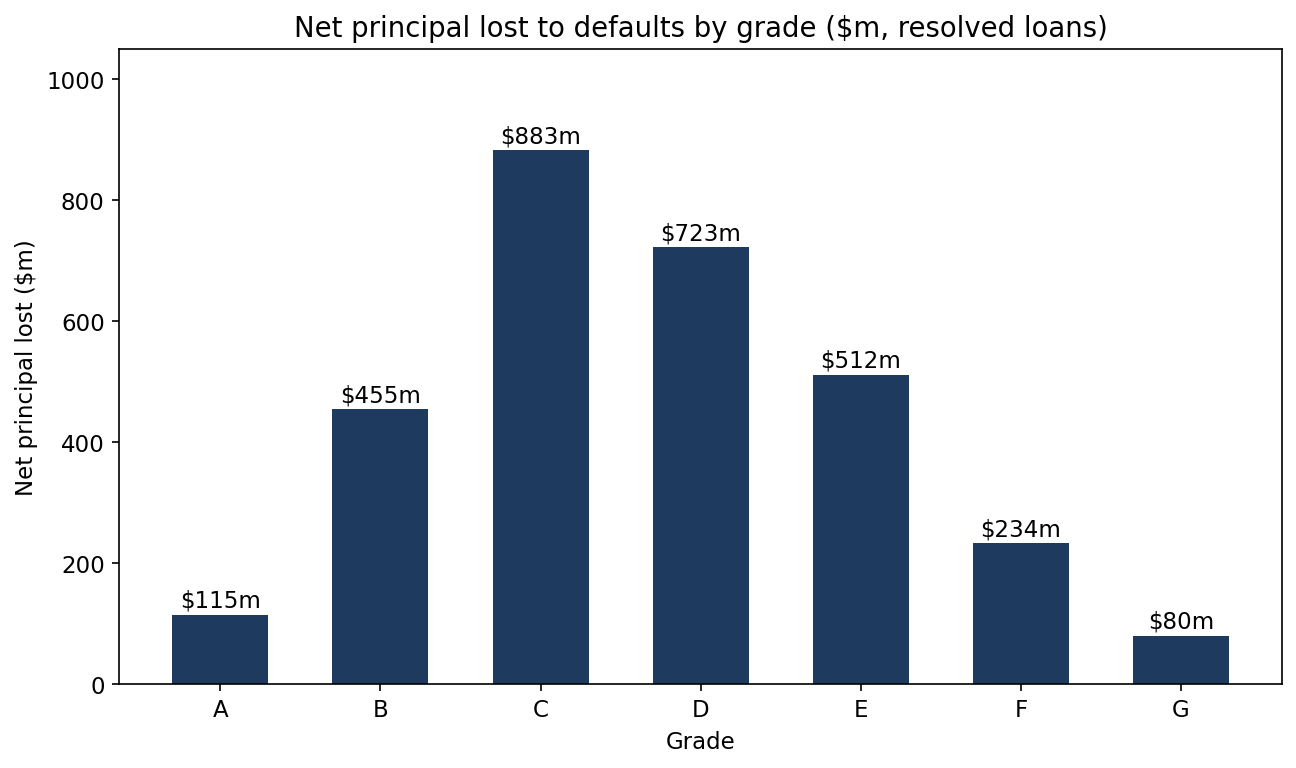

In [ ]:
# see sql/ for the query behind this chart
from IPython.display import Image
Image('images/net_loss_by_grade.png')

## Stretch model — logistic regression (application-time features only)

ROC-AUC on a held-out 20% test set: **0.690**. Grade, sub-grade and interest rate are deliberately excluded: they are the lender's own post-application assessment, so a granting model cannot use them. Post-origination fields (payments received, recoveries) would leak the outcome. Full odds ratios are in `notebooks/model_results.txt`.

In [ ]:
# Model code lives in notebooks/build_notebook.py (reproducible end to end).
# Features: fico, dti, log(annual_inc), emp_length_years, log(loan_amnt),
# term_months + dummies for home_ownership, purpose, verification_status.
# LogisticRegression(class_weight='balanced'), 80/20 stratified split.